In [1]:
import os
import sys

project_root = os.path.abspath("../..")

sys.path.insert(0, project_root)

print("Project folder:", project_root)
print("Files:", os.listdir(project_root))

Project folder: c:\Petya\HST_BSc\Foundations of Data Science\nhanes-inflammation-chd
Files: ['.git', '.gitignore', '.venv', 'data', 'notebooks', 'prepare_data.py', 'README.md', 'reports', 'requirements.txt']


## 1. Introduction and modelling objective

The objective of this analysis is to evaluate whether inflammatory biomarkers improve the prediction of self-reported coronary heart disease or myocardial infarction (CHD/MI) among US adults.

Two regularised logistic regression methods are used:

- **Lasso (L1 regularisation):** encourages sparse models by shrinking some coefficients to zero.
- **Ridge (L2 regularisation):** shrinks coefficients towards zero while generally retaining predictors.

The analysis compares four progressively expanded feature sets (M0–M3). The main focus is whether adding neutrophil-to-lymphocyte ratio (NLR) and high-sensitivity C-reactive protein (hs-CRP) improves predictive performance beyond established cardiovascular risk factors.

### Data and train/test split

The analysis uses the shared data-preparation pipeline provided by the project. The function `load_data(split=True)` loads the prepared dataset and returns the training and test sets.

The shared preparation script defines the study cohort and the train/test split. These steps are not repeated or modified in this notebook, ensuring consistency with the other analyses in the project.

The training set is used for model fitting and hyperparameter tuning. The test set is held out and used only for the final evaluation of model performance.

In [2]:
from prepare_data import load_data

train, test = load_data(split=True)

print("Training data:", train.shape)
print("Test data:", test.shape)

Training data: (3635, 35)
Test data: (909, 35)


In [3]:
print("ALL AVAILABLE VARIABLES:")
print(train.columns.tolist())

ALL AVAILABLE VARIABLES:
['SEQN', 'chd_mi', 'chd', 'mi', 'angina', 'crp', 'crp_below_lod', 'crp_above_10', 'log_crp', 'nlr', 'log_nlr', 'wbc', 'age', 'male', 'race_eth', 'income_pir', 'education', 'bmi', 'smoking', 'diabetes', 'sbp', 'dbp', 'hypertension', 'total_chol', 'hdl_chol', 'creatinine', 'egfr', 'lipid_med', 'bp_med', 'weight_mec', 'strata', 'psu', 'exam_status', 'complete_case', 'split']


In [4]:
print("Available variables:")
print(train.columns.tolist())

Available variables:
['SEQN', 'chd_mi', 'chd', 'mi', 'angina', 'crp', 'crp_below_lod', 'crp_above_10', 'log_crp', 'nlr', 'log_nlr', 'wbc', 'age', 'male', 'race_eth', 'income_pir', 'education', 'bmi', 'smoking', 'diabetes', 'sbp', 'dbp', 'hypertension', 'total_chol', 'hdl_chol', 'creatinine', 'egfr', 'lipid_med', 'bp_med', 'weight_mec', 'strata', 'psu', 'exam_status', 'complete_case', 'split']


In [5]:
print("Training dataset:")
print(train.head())

Training dataset:
     SEQN  chd_mi  chd   mi  angina   crp  crp_below_lod  crp_above_10  \
0  130378     0.0  0.0  0.0     0.0  1.78            0.0           0.0   
1  130379     0.0  0.0  0.0     0.0  2.03            0.0           0.0   
4  130387     0.0  0.0  0.0     0.0  3.96            0.0           0.0   
6  130391     0.0  0.0  0.0     0.0  3.55            0.0           0.0   
7  130392     0.0  0.0  0.0     0.0  9.46            0.0           0.0   

    log_crp       nlr  ...  creatinine        egfr  lipid_med  bp_med  \
0  0.576613  1.129902  ...        0.80  112.614180        0.0     1.0   
1  0.708036  2.255906  ...        0.79   97.975999        0.0     1.0   
4  1.376244  3.433498  ...        0.76   85.298556        0.0     1.0   
6  1.266948  2.488722  ...        0.55  124.044304        0.0     0.0   
7  2.247072  1.845659  ...        0.59   94.512138        0.0     1.0   

     weight_mec  strata  psu  exam_status complete_case  split  
0  54374.463898   173.0  2.0     

In [6]:
print(train["chd_mi"].value_counts(dropna=False))

chd_mi
0.0    3365
1.0     270
Name: count, dtype: int64


In [7]:
print("VARIABLE TYPES:")
print(train.dtypes)

print("\nMISSING VALUES:")
print(train.isnull().sum())

VARIABLE TYPES:
SEQN               int64
chd_mi           float64
chd              float64
mi               float64
angina           float64
crp              float64
crp_below_lod    float64
crp_above_10     float64
log_crp          float64
nlr              float64
log_nlr          float64
wbc              float64
age              float64
male             float64
race_eth             str
income_pir       float64
education        float64
bmi              float64
smoking              str
diabetes         float64
sbp              float64
dbp              float64
hypertension     float64
total_chol       float64
hdl_chol         float64
creatinine       float64
egfr             float64
lipid_med        float64
bp_med           float64
weight_mec       float64
strata           float64
psu              float64
exam_status      float64
complete_case       bool
split                str
dtype: object

MISSING VALUES:
SEQN              0
chd_mi            0
chd               4
mi                

## 2. Definition of the feature sets

Four progressively expanded feature sets are defined to examine how predictive performance changes as additional groups of cardiovascular risk factors and inflammatory biomarkers are included.

- **M0 – Demographic baseline:** age and sex.
- **M1 – Demographic and socioeconomic factors:** M0 plus BMI, race/ethnicity and income-to-poverty ratio.
- **M2 – Established cardiovascular risk factors:** M1 plus smoking status, diabetes, hypertension, total cholesterol, HDL cholesterol and estimated glomerular filtration rate (eGFR).
- **M3 – Inflammatory biomarkers:** M2 plus log-transformed neutrophil-to-lymphocyte ratio (log-NLR) and log-transformed C-reactive protein (log-CRP).

This staged model structure allows us to compare the predictive performance of models with and without the two inflammatory biomarkers, while retaining the same established risk factors in M2 and M3.

The feature sets are defined before model fitting and are used consistently for both Lasso and Ridge logistic regression.

In [8]:
features = {
    "M0": [
        "age",
        "male"
    ],

    "M1": [
        "age", "male",
        "bmi", "race_eth", "income_pir"
    ],

    "M2": [
        "age", "male",
        "bmi", "race_eth", "income_pir",
        "smoking", "diabetes", "hypertension",
        "total_chol", "hdl_chol", "egfr"
    ],

    "M3": [
        "age", "male",
        "bmi", "race_eth", "income_pir",
        "smoking", "diabetes", "hypertension",
        "total_chol", "hdl_chol", "egfr",
        "log_nlr", "log_crp"
    ]
}

print("Model definitions:")

for model, variables in features.items():
    print(model, ":", variables)

Model definitions:
M0 : ['age', 'male']
M1 : ['age', 'male', 'bmi', 'race_eth', 'income_pir']
M2 : ['age', 'male', 'bmi', 'race_eth', 'income_pir', 'smoking', 'diabetes', 'hypertension', 'total_chol', 'hdl_chol', 'egfr']
M3 : ['age', 'male', 'bmi', 'race_eth', 'income_pir', 'smoking', 'diabetes', 'hypertension', 'total_chol', 'hdl_chol', 'egfr', 'log_nlr', 'log_crp']


## 3. Data preprocessing

Before fitting the models, the features are preprocessed using a scikit-learn `ColumnTransformer` and separate pipelines for numerical and categorical variables.

**Numerical variables**

- Missing values are replaced using the median.
- Variables are standardised using `StandardScaler`.

**Categorical features**

- Missing values are replaced using the most frequent category.
- Categories are converted into numerical indicator variables using one-hot encoding.
- `handle_unknown="ignore"` allows the encoder to handle categories that were not encountered when it was fitted.

The preprocessing steps are incorporated into a scikit-learn `Pipeline` together with the logistic regression model. This is important because, during cross-validation, preprocessing is fitted separately within each training fold. It helps prevent information from the validation folds from leaking into the model-fitting process.

The same preprocessing approach is used for both Lasso and Ridge models.

In [9]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

In [14]:
def create_preprocessor(X):
    categorical_features = [
        col for col in ["race_eth", "smoking"]
        if col in X.columns
    ]

    numerical_features = [
        col for col in X.columns
        if col not in categorical_features
    ]

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers = [
        ("numerical", numerical_pipeline, numerical_features)
    ]

    if categorical_features:
        transformers.append(
            ("categorical", categorical_pipeline, categorical_features)
        )

    preprocessor = ColumnTransformer(transformers)

    return preprocessor

In [12]:
X_check = train[features["M3"]]

preprocessor = create_preprocessor(X_check)

X_processed = preprocessor.fit_transform(X_check)

print("Original data shape:", X_check.shape)
print("Processed data shape:", X_processed.shape)

Original data shape: (3635, 13)
Processed data shape: (3635, 20)


## 4. Model training and hyperparameter tuning

Lasso and Ridge logistic regression models are trained using the four feature sets (M0–M3).

**Cross-validation**

Stratified 5-fold cross-validation is used to evaluate each combination of model type and feature set. Stratification maintains approximately the same proportion of CHD/MI cases in each fold as in the full training set.

**Hyperparameter tuning**

For each model, `GridSearchCV` tests six values of the regularisation parameter `C`:

`[0.001, 0.01, 0.1, 1, 10, 100]`

The value of `C` controls the strength of regularisation: smaller values correspond to stronger regularisation, while larger values correspond to weaker regularisation.

- **Lasso logistic regression** uses L1 regularisation.
- **Ridge logistic regression** uses L2 regularisation.

The combination of model type, feature set and `C` is evaluated using ROC-AUC as the cross-validation scoring metric. The combination with the highest mean cross-validation ROC-AUC is selected.

All model fitting and hyperparameter tuning are performed using the training set. The held-out test set is reserved for the final evaluation and is not used during model selection.

In [15]:
# Set up cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Values of C to test
C_values = [0.001, 0.01, 0.1, 1, 10, 100]

# Store the trained models and their results
best_models = {}
cv_results = []

# Train Lasso (L1) and Ridge (L2) models for M0-M3
for model_type, penalty in [("Lasso", "l1"), ("Ridge", "l2")]:

    for model_name, selected_features in features.items():

        X_train = train[selected_features]
        y_train = train["chd_mi"]

        # Create preprocessing and logistic regression pipeline
        pipeline = Pipeline([
            ("preprocessor", create_preprocessor(X_train)),
            ("model", LogisticRegression(
                penalty=penalty,
                solver="liblinear",
                max_iter=5000,
                random_state=42
            ))
        ])

        # Find the best regularisation strength
        search = GridSearchCV(
            pipeline,
            param_grid={"model__C": C_values},
            scoring="roc_auc",
            cv=cv,
            n_jobs=-1
        )

        search.fit(X_train, y_train)

        # Save the best model
        best_models[(model_type, model_name)] = search.best_estimator_

        # Save cross-validation results
        cv_results.append({
            "Model": model_type,
            "Feature set": model_name,
            "Best C": search.best_params_["model__C"],
            "Mean CV ROC-AUC": search.best_score_
        })

# Display results
cv_results_df = pd.DataFrame(cv_results)
cv_results_df

c:\Users\petya\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\petya\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\petya\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 

,Model,Feature set,Best C,Mean CV ROC-AUC
0,Lasso,M0,1.0,0.797722
1,Lasso,M1,0.1,0.810745
2,Lasso,M2,0.1,0.858703
3,Lasso,M3,0.1,0.859446
4,Ridge,M0,0.1,0.797969
5,Ridge,M1,0.1,0.806574
6,Ridge,M2,0.1,0.858340
7,Ridge,M3,0.1,0.857960


## 5. Evaluation on the held-out test set

After hyperparameter tuning, the selected Lasso and Ridge models are evaluated on the held-out test set. This provides an assessment of how well the models perform on data that were not used for model fitting or hyperparameter selection.

Three performance metrics are calculated:

- **ROC-AUC (Area Under the Receiver Operating Characteristic Curve):** measures the model's ability to distinguish between individuals with and without CHD/MI. Higher values indicate better discrimination.
- **PR-AUC (Area Under the Precision-Recall Curve):** summarises the trade-off between precision and recall. This metric is particularly informative when the outcome classes are imbalanced, as in this dataset.
- **Brier score:** measures the accuracy of predicted probabilities by calculating the mean squared difference between predicted probabilities and observed outcomes. Lower values indicate better probabilistic predictions.

The same held-out test set is used to evaluate all Lasso and Ridge models across feature sets M0–M3, allowing their performance to be compared consistently.

The test-set results are interpreted alongside the cross-validation results. In particular, the comparison between M2 and M3 examines whether adding log-NLR and log-CRP improves predictive performance beyond the established cardiovascular risk factors.

In [16]:
# Evaluate the final models on the test dataset

test_results = []

for (model_type, model_name), model in best_models.items():

    X_test = test[features[model_name]]
    y_test = test["chd_mi"]

    # Predicted probability of CHD/MI
    y_pred = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    test_results.append({
        "Model": model_type,
        "Feature set": model_name,
        "ROC-AUC": roc_auc_score(y_test, y_pred),
        "PR-AUC": average_precision_score(y_test, y_pred),
        "Brier score": brier_score_loss(y_test, y_pred)
    })

test_results_df = pd.DataFrame(test_results)

test_results_df.round(4)

,Model,Feature set,ROC-AUC,PR-AUC,Brier score
0,Lasso,M0,0.8094,0.1956,0.0628
1,Lasso,M1,0.8272,0.2557,0.0614
2,Lasso,M2,0.8723,0.4308,0.0538
3,Lasso,M3,0.8751,0.4488,0.0531
4,Ridge,M0,0.8131,0.1990,0.0626
5,Ridge,M1,0.8339,0.2846,0.0607
6,Ridge,M2,0.8808,0.4723,0.0524
7,Ridge,M3,0.8842,0.4908,0.0515


## 6. Bootstrap comparison of ROC-AUC

To assess the uncertainty in the improvement in discrimination associated with adding the inflammatory biomarkers, a bootstrap analysis is performed on the held-out test set.

For each model type, the difference in ROC-AUC between M3 (established cardiovascular risk factors plus log-NLR and log-CRP) and M2 (established cardiovascular risk factors only) is calculated:

**Δ ROC-AUC = ROC-AUC (M3) − ROC-AUC (M2)**

Bootstrap resampling is used to estimate a 95% confidence interval for this difference. The analysis uses 2,000 bootstrap samples drawn from the held-out test observations.

A positive difference indicates higher ROC-AUC for M3. If the 95% confidence interval includes zero, the data do not provide clear evidence of an improvement in ROC-AUC after adding the inflammatory biomarkers.

This comparison evaluates the incremental predictive value of the inflammatory features. It does not, by itself, establish whether NLR or hs-CRP is independently associated with CHD/MI.

In [17]:
# Bootstrap confidence intervals for the change in ROC-AUC
# Comparing M3 against M2

def bootstrap_auc_difference(
    y_true, pred_m2, pred_m3, n_bootstrap=2000
):
    rng = np.random.default_rng(42)

    differences = []

    y_true = np.asarray(y_true)
    pred_m2 = np.asarray(pred_m2)
    pred_m3 = np.asarray(pred_m3)

    for _ in range(n_bootstrap):

        indices = rng.choice(
            len(y_true),
            size=len(y_true),
            replace=True
        )

        y_sample = y_true[indices]

        # AUC requires both outcome classes
        if len(np.unique(y_sample)) < 2:
            continue

        auc_m2 = roc_auc_score(
            y_sample, pred_m2[indices]
        )

        auc_m3 = roc_auc_score(
            y_sample, pred_m3[indices]
        )

        differences.append(auc_m3 - auc_m2)

    lower = np.percentile(differences, 2.5)
    upper = np.percentile(differences, 97.5)

    return lower, upper


# Calculate predictions for M2 and M3
y_test = test["chd_mi"].to_numpy()

for model_type in ["Lasso", "Ridge"]:

    pred_m2 = best_models[(model_type, "M2")].predict_proba(
        test[features["M2"]]
    )[:, 1]

    pred_m3 = best_models[(model_type, "M3")].predict_proba(
        test[features["M3"]]
    )[:, 1]

    difference = (
        roc_auc_score(y_test, pred_m3)
        - roc_auc_score(y_test, pred_m2)
    )

    lower, upper = bootstrap_auc_difference(
        y_test, pred_m2, pred_m3
    )

    print(f"\n{model_type}")
    print(f"Change in ROC-AUC (M3 - M2): {difference:.4f}")
    print(f"95% bootstrap CI: ({lower:.4f}, {upper:.4f})")


Lasso
Change in ROC-AUC (M3 - M2): 0.0027
95% bootstrap CI: (-0.0021, 0.0080)

Ridge
Change in ROC-AUC (M3 - M2): 0.0034
95% bootstrap CI: (-0.0015, 0.0084)


## 7. Examination of model coefficients

The fitted Lasso and Ridge models are examined to understand how individual features contribute to the model's predictions.

Predictive performance is compared across all four feature sets (M0–M3). For a more detailed examination of the individual feature contributions, the coefficients of the two M3 models are extracted after preprocessing. M3 is selected because it includes both established cardiovascular risk factors and the two inflammatory biomarkers (log-NLR and log-CRP).

Numerical features have been standardised, and categorical features have been one-hot encoded.

**Lasso (L1 regularisation)** can shrink some coefficients to exactly zero, effectively excluding the corresponding transformed features from the model.

**Ridge (L2 regularisation)** shrinks coefficients towards zero but generally retains all features.

The sign of a coefficient indicates the direction of its contribution to the predicted log-odds of CHD/MI, conditional on the other features in the model:

- A positive coefficient contributes towards a higher predicted probability of CHD/MI.
- A negative coefficient contributes towards a lower predicted Fprobability of CHD/MI.

Coefficient magnitudes should be interpreted cautiously because numerical features are standardised and categorical features are one-hot encoded. These coefficients are model parameters, not tests of statistical significance, and should not be interpreted as evidence of independent associations or causal effects.

In [18]:
# Examine the Lasso M3 model coefficients

lasso_m3 = best_models[("Lasso", "M3")]

# Get the fitted preprocessing step
preprocessor = lasso_m3.named_steps["preprocessor"]

# Get the fitted logistic regression model
logistic_model = lasso_m3.named_steps["model"]

# Get the names of the transformed predictors
feature_names = preprocessor.get_feature_names_out()

# Get their coefficients
coefficients = logistic_model.coef_[0]

# Create a results table
lasso_coefficients = pd.DataFrame({
    "Predictor": feature_names,
    "Coefficient": coefficients
})

# Add a column indicating whether the coefficient is zero
lasso_coefficients["Selected"] = (
    lasso_coefficients["Coefficient"] != 0
)

# Sort by absolute coefficient size
lasso_coefficients["Absolute coefficient"] = (
    lasso_coefficients["Coefficient"].abs()
)

lasso_coefficients = lasso_coefficients.sort_values(
    "Absolute coefficient",
    ascending=False
)

lasso_coefficients.round(4)

,Predictor,Coefficient,Selected,Absolute coefficient
0,numerical__age,0.8501,True,0.8501
19,categorical__smoking_never,-0.5791,True,0.5791
6,numerical__total_chol,-0.4911,True,0.4911
5,numerical__hypertension,0.2826,True,0.2826
4,numerical__diabetes,0.1972,True,0.1972
8,numerical__egfr,-0.1704,True,0.1704
7,numerical__hdl_chol,-0.1568,True,0.1568
1,numerical__male,0.1248,True,0.1248
9,numerical__log_nlr,0.1069,True,0.1069
3,numerical__income_pir,-0.0471,True,0.0471


In [19]:
# Examine the Ridge M3 model coefficients

ridge_m3 = best_models[("Ridge", "M3")]

preprocessor = ridge_m3.named_steps["preprocessor"]
logistic_model = ridge_m3.named_steps["model"]

feature_names = preprocessor.get_feature_names_out()
coefficients = logistic_model.coef_[0]

ridge_coefficients = pd.DataFrame({
    "Predictor": feature_names,
    "Coefficient": coefficients
})

ridge_coefficients["Absolute coefficient"] = (
    ridge_coefficients["Coefficient"].abs()
)

ridge_coefficients = ridge_coefficients.sort_values(
    "Absolute coefficient",
    ascending=False
)

ridge_coefficients.round(4)


,Predictor,Coefficient,Absolute coefficient
19,categorical__smoking_never,-1.1329,1.1329
0,numerical__age,0.7729,0.7729
13,categorical__race_eth_nh_black,-0.5793,0.5793
11,categorical__race_eth_mexican_american,-0.5682,0.5682
18,categorical__smoking_former,-0.5430,0.5430
6,numerical__total_chol,-0.4876,0.4876
17,categorical__smoking_current,-0.3938,0.3938
16,categorical__race_eth_other_multi,-0.3742,0.3742
5,numerical__hypertension,0.2957,0.2957
14,categorical__race_eth_nh_white,-0.2688,0.2688


## 8. Calibration analysis

In addition to discrimination, the calibration of the predicted probabilities is examined for the Ridge M3 model.

Calibration assesses how closely the predicted probabilities agree with the observed frequency of CHD/MI. A well-calibrated model should, for example, have an observed CHD/MI frequency of approximately 10% among individuals assigned a predicted probability of 10%.

A calibration curve is generated by grouping observations according to their predicted probabilities and comparing the mean predicted probability with the observed outcome frequency in each group.

Two additional calibration measures are calculated:

- **Brier score:** measures the overall accuracy of predicted probabilities, with lower values indicating better performance.
- **Calibration intercept and slope:** assess systematic differences between predicted and observed risk. Ideally, the intercept is 0 and the slope is 1.

Calibration is examined for Ridge M3 only, so these results should not be generalised to all fitted models.

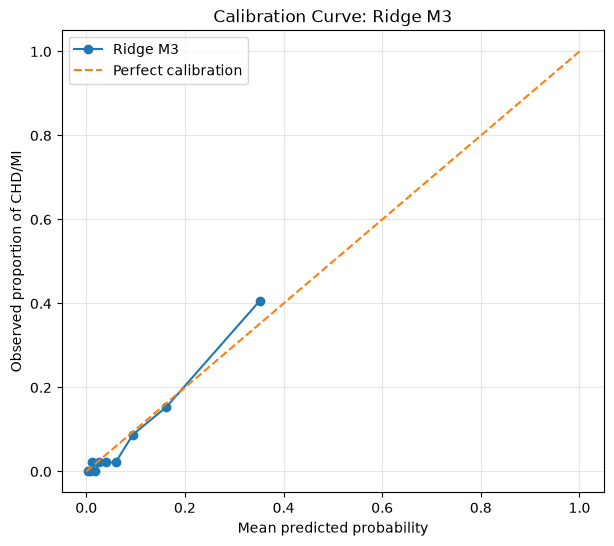

In [20]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Ridge M3 predictions
ridge_m3 = best_models[("Ridge", "M3")]

y_test = test["chd_mi"]
y_pred = ridge_m3.predict_proba(
    test[features["M3"]]
)[:, 1]

# Calculate calibration values
observed, predicted = calibration_curve(
    y_test,
    y_pred,
    n_bins=10,
    strategy="quantile"
)

# Plot calibration curve
plt.figure(figsize=(7, 6))

plt.plot(
    predicted,
    observed,
    marker="o",
    label="Ridge M3"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed proportion of CHD/MI")
plt.title("Calibration Curve: Ridge M3")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
# Show the numerical calibration results

calibration_results = pd.DataFrame({
    "Mean predicted probability": predicted,
    "Observed CHD/MI proportion": observed
})

calibration_results.round(4)

,Mean predicted probability,Observed CHD/MI proportion
0,0.0039,0.0000
1,0.0075,0.0000
2,0.0115,0.0220
3,0.0180,0.0000
4,0.0255,0.0220
5,0.0393,0.0222
6,0.0596,0.0220
7,0.0945,0.0879
8,0.1626,0.1538
9,0.3519,0.4066


In [23]:
from sklearn.linear_model import LogisticRegression

# Calibration intercept and slope
# Use the predicted probabilities from Ridge M3

eps = 1e-6

logit_pred = np.log(
    np.clip(y_pred, eps, 1 - eps) /
    (1 - np.clip(y_pred, eps, 1 - eps))
).reshape(-1, 1)

calibration_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=5000
)

calibration_model.fit(logit_pred, y_test)

print("Calibration intercept:",
      calibration_model.intercept_[0].round(4))

print("Calibration slope:",
      calibration_model.coef_[0][0].round(4))

print("Brier score:",
      round(brier_score_loss(y_test, y_pred), 4))

Calibration intercept: 0.4275
Calibration slope: 1.2931
Brier score: 0.0515


c:\Users\petya\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [24]:
# Recalculate calibration intercept and slope without regularisation

calibration_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=5000
)

calibration_model.fit(logit_pred, y_test)

print("Calibration intercept:",
      round(calibration_model.intercept_[0], 4))

print("Calibration slope:",
      round(calibration_model.coef_[0][0], 4))

Calibration intercept: 0.4275
Calibration slope: 1.2931


c:\Users\petya\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


## Results and interpretation

### Model performance

Predictive performance improved substantially from M0 to M2 for both Lasso and Ridge logistic regression. Adding established cardiovascular risk factors improved discrimination compared with the age- and sex-only baseline.

Adding log-transformed NLR and hs-CRP in M3 resulted in a small further improvement in test-set performance.

For Lasso, test ROC-AUC increased from 0.8723 in M2 to 0.8751 in M3. For Ridge, it increased from 0.8808 to 0.8842. The corresponding PR-AUC values also increased, while Brier scores decreased slightly.

Overall, Ridge achieved slightly better test-set performance than Lasso across the four feature sets.

### Bootstrap comparison

The bootstrap confidence interval for the change in ROC-AUC between M3 and M2 included zero for both methods:

- Lasso: ΔAUC = 0.0027, 95% CI −0.0021 to 0.0080.
- Ridge: ΔAUC = 0.0034, 95% CI −0.0015 to 0.0084.

Therefore, although M3 showed slightly better point estimates, the results do not provide clear evidence of an improvement in ROC-AUC from adding NLR and hs-CRP.

### Feature coefficients

In the Lasso M3 model, log-NLR retained a positive coefficient (0.1069), whereas log-CRP was assigned a coefficient of zero. This indicates that, under the selected regularisation strength, log-NLR was retained in the model, whereas log-CRP was excluded.

In the Ridge M3 model, log-NLR also had a positive coefficient (0.1197), while log-CRP had a small negative coefficient (−0.0156). Ridge retained all transformed features but shrank their coefficients towards zero.

These coefficients are on the transformed feature scale. They should not be interpreted as odds ratios or as evidence of statistical significance or independent association.

### Calibration

The Ridge M3 model achieved a Brier score of 0.0515, a calibration intercept of 0.4275 and a calibration slope of 1.2931.

The calibration slope being greater than 1 suggests that the predicted probabilities were less spread out than the observed risks, indicating predictions that were insufficiently extreme. The positive calibration intercept, interpreted together with the slope, also indicates a departure from ideal calibration.

The calibration plot suggested some underprediction in the highest-risk group.

### Overall conclusion

Both Lasso and Ridge models showed that established cardiovascular risk factors substantially improved prediction of self-reported CHD/MI compared with the age- and sex-only baseline.

Adding NLR and hs-CRP produced a small additional improvement in predictive performance. However, the bootstrap confidence intervals included zero, so this improvement was not conclusive.

The positive log-NLR coefficients in both models suggest that NLR contributes positively to the fitted models' predicted log-odds of CHD/MI. In contrast, hs-CRP had little contribution to the fitted models under the selected regularisation settings.

These predictive findings do not establish whether NLR or hs-CRP is independently associated with CHD/MI. That question requires separate inferential analyses. The findings should also be interpreted in light of the complete-case sample, the relatively small number of CHD/MI cases, and the limitations of self-reported outcome data.